# Análise exploratória dos dados



total de classes (nível espécie): 1924

total de classes (nível familia): 264

total de classes (nível ordem): 28

total de imagens: 244.557

Os dados não estão com uma boa distribuição, mas com a arquitetura prevista podemos resolver o problema.

Treinar yolo26 para detectar a ordem do inseto, 1 modelo
Descoberta a ordem: treinar para descobrir a família dentro da ordem, 27 modelos
Descoberta a família: treinar para descobrir a espécie dentro da ordem, 264 modelos (viável?)

Possíveis melhorias: fazer segmentação das imagens para separar o fundo da imagem do inseto (Pegar modelos prontos ou fazer fine tunning usando datasets já segmentados e testar)

In [4]:
%pip install split-folders pandas matplotlib seaborn scikit-learn

  Using cached pandas-3.1.0-cp312-cp312-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (18 kB)
  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.2/137.2 kB 2.6 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 39.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 31.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 20.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 35.4 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 37.9 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [5]:
# imports
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import os
from PIL import Image
import splitfolders


In [2]:
def get_df(path):
    
    dataset_path = Path(path)

    data = []

    for pasta_categoria in dataset_path.iterdir():
        if pasta_categoria.is_dir():
            categoria_nome = pasta_categoria.name
            
            total_imagens = sum(1 for arquivo in pasta_categoria.iterdir())
            
            data.append({
                "categoria": categoria_nome,
                "quantidade_imagens": total_imagens
            })
    df = pd.DataFrame(data)
    return df


In [3]:
# métricas a nivel de espécie
df_species = get_df('/home/bradachi/Downloads/datasets/final/especies')
df_species

,categoria,quantidade_imagens
0,Zelus luridus,53
1,Haematopinus asini,43
2,Bembidion decorum,320
3,Agrotis orthogonia,62
4,Leptogaster,56
...,...,...
1919,Trypodendron lineatum,92
1920,Notiophilus palustris,284
1921,Xanthogaleruca luteola,77
1922,Campsomeris,52


In [4]:
df_species['quantidade_imagens'].describe()

count    1924.000000
mean      127.108628
std       170.869226
min         2.000000
25%        54.000000
50%        68.000000
75%       105.000000
max      1374.000000
Name: quantidade_imagens, dtype: float64

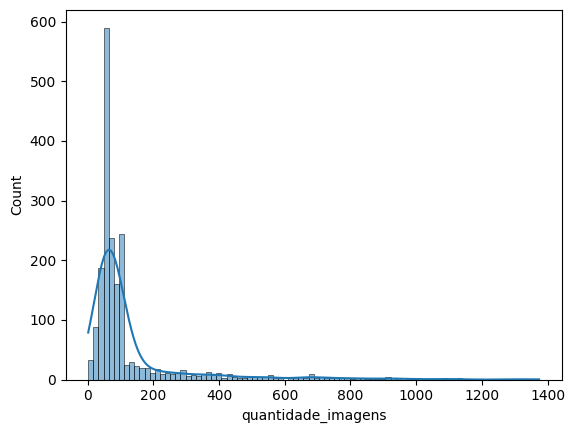

In [14]:
sns.histplot(data=df_species, x='quantidade_imagens', kde=True)
plt.show()


In [5]:
# métricas a nivel de familia
df_familia = get_df('/home/bradachi/Downloads/datasets/familia')
df_familia

,categoria,quantidade_imagens
0,Calliphoridae,342
1,Tungidae,19
2,Lygaeidae,400
3,Gracillariidae,765
4,Scutigerellidae,46
...,...,...
259,Cleridae,1053
260,Tettigoniidae,599
261,Papilionidae,855
262,Cossidae,240


In [6]:
df_familia['quantidade_imagens'].describe()

count      264.000000
mean       925.113636
std       4382.472970
min          3.000000
25%         61.750000
50%        157.000000
75%        571.250000
max      67879.000000
Name: quantidade_imagens, dtype: float64

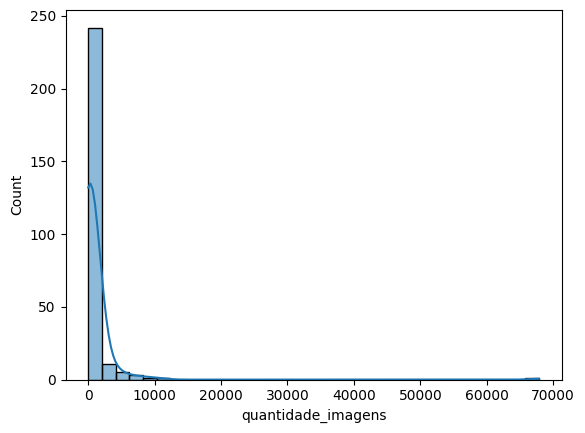

In [11]:
sns.histplot(data=df_familia, x='quantidade_imagens', kde=True)
plt.show()

In [7]:
# métricas a nivel de ordem
df_ordem = get_df('/home/bradachi/Downloads/datasets/ordem')
df_ordem

,categoria,quantidade_imagens
0,Thysanoptera,3187
1,Diptera,17375
2,Mantodea,222
3,Embioptera,32
4,Coleoptera,103588
5,Blattodea,1736
6,Phasmida,158
7,Hymenoptera,23349
8,Mesostigmata,171
9,Neuroptera,352


In [8]:
df_ordem['quantidade_imagens'].describe()

count        28.000000
mean       8722.500000
std       21699.790585
min          28.000000
25%         209.250000
50%         651.000000
75%        2446.000000
max      103588.000000
Name: quantidade_imagens, dtype: float64

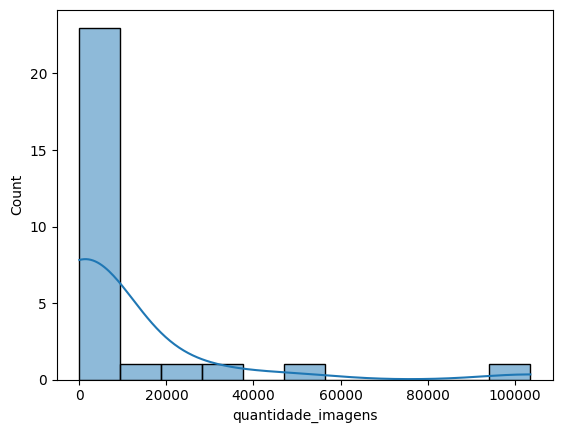

In [12]:
sns.histplot(data=df_ordem, x='quantidade_imagens', kde=True)
plt.show()

In [4]:
dados = list()
def metrica_resolucao(pasta_imagens):
    # Extensões válidas de imagem

    print(pasta_imagens)
    extensoes_validas = (".png", ".jpg", ".jpeg", ".bmp", ".gif", ".tiff")

    larguras = []
    alturas = []

    # Percorre todos os arquivos da pasta
    for arquivo in os.listdir(pasta_imagens):
        if arquivo.lower().endswith(extensoes_validas):
            caminho_completo = os.path.join(pasta_imagens, arquivo)
            try:
                with Image.open(caminho_completo) as img:
                    largura, altura = img.size
                    larguras.append(largura)
                    alturas.append(altura)
            except Exception as e:
                print(f"Erro ao abrir o arquivo {arquivo}: {e}")

    # Calcula a média se houver imagens
    if len(larguras) > 0:
        media_largura = sum(larguras) / len(larguras)
        media_altura = sum(alturas) / len(alturas)
        
        print(f"Total de imagens analisadas: {len(larguras)}")
        print(f"Resolução média: {media_largura:.2f} x {media_altura:.2f} pixels")
        dados.append((media_largura, media_altura))
        print(f"Resolução média arredondada: {round(media_largura)} x {round(media_altura)} pixels")
    else:
        print("Nenhuma imagem válida encontrada na pasta.")

def dataset_resolucao(pasta_origem):
    for arquivo in os.listdir(pasta_origem):
        metrica_resolucao(f'{pasta_origem}/{arquivo}')


In [5]:
dataset_resolucao("/home/bradachi/Downloads/datasets/ordem")

/home/bradachi/Downloads/datasets/ordem/Thysanoptera
Total de imagens analisadas: 3186
Resolução média: 562.84 x 444.27 pixels
Resolução média arredondada: 563 x 444 pixels
/home/bradachi/Downloads/datasets/ordem/Diptera
Total de imagens analisadas: 17367
Resolução média: 502.74 x 412.07 pixels
Resolução média arredondada: 503 x 412 pixels
/home/bradachi/Downloads/datasets/ordem/Mantodea
Total de imagens analisadas: 222
Resolução média: 523.01 x 414.50 pixels
Resolução média arredondada: 523 x 414 pixels
/home/bradachi/Downloads/datasets/ordem/Embioptera
Total de imagens analisadas: 32
Resolução média: 523.44 x 375.69 pixels
Resolução média arredondada: 523 x 376 pixels
/home/bradachi/Downloads/datasets/ordem/Coleoptera
Total de imagens analisadas: 103570
Resolução média: 413.22 x 516.00 pixels
Resolução média arredondada: 413 x 516 pixels
/home/bradachi/Downloads/datasets/ordem/Blattodea
Total de imagens analisadas: 1730
Resolução média: 607.98 x 452.82 pixels
Resolução média arredond

/home/bradachi/Documentos/gitpath/ML-engineering-final-project/.venv/lib/python3.12/site-packages/PIL/Image.py:3593: DecompressionBombWarning: Image size (122922240 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


Total de imagens analisadas: 23347
Resolução média: 476.93 x 407.34 pixels
Resolução média arredondada: 477 x 407 pixels
/home/bradachi/Downloads/datasets/ordem/Mesostigmata
Total de imagens analisadas: 171
Resolução média: 383.42 x 317.98 pixels
Resolução média arredondada: 383 x 318 pixels
/home/bradachi/Downloads/datasets/ordem/Neuroptera
Total de imagens analisadas: 352
Resolução média: 640.80 x 469.15 pixels
Resolução média arredondada: 641 x 469 pixels
/home/bradachi/Downloads/datasets/ordem/Symphypleona
Total de imagens analisadas: 28
Resolução média: 391.43 x 281.43 pixels
Resolução média arredondada: 391 x 281 pixels
/home/bradachi/Downloads/datasets/ordem/Psocodea
Total de imagens analisadas: 1072
Resolução média: 429.76 x 345.90 pixels
Resolução média arredondada: 430 x 346 pixels
/home/bradachi/Downloads/datasets/ordem/Trombidiformes
Total de imagens analisadas: 2198
Resolução média: 513.04 x 397.21 pixels
Resolução média arredondada: 513 x 397 pixels
/home/bradachi/Downloa

In [ ]:
# Estatística das médias do tamanho de imagem por classe
df = pd.DataFrame(dados)
df.describe()


,0,1
count,27.000000,27.000000
mean,488.151415,394.580996
std,107.175996,77.038750
min,152.502116,147.868829
25%,428.749468,358.595282
50%,502.741176,403.338983
75%,551.685909,441.324967
max,712.142857,530.561224


Acredito que redimencionar as imagens para 512x512 vai ser uma boa opção

In [ ]:
# dataset real
input_folder = "/home/bradas/Downloads/ordem"

# Pasta de saída que será criada com os subconjuntos
output_folder = "/home/bradas/Downloads/ordem_yolo"

# Dividindo na proporção: 80% treino e 20% teste
splitfolders.ratio(
    input_folder,
    output=output_folder,
    seed=1337,
    ratio=(0.8, 0.2),  # (treino, teste)
)

In [ ]:
# toy dataset
splitfolders.ratio(
    input_folder,
    output="/home/bradas/Downloads/ordem_yolo_toy",
    seed=1337,
    ratio=(0.94, 0.05, 0.01),  # (descarte, treino, teste)
)